# Worked example: three questions, answered and checked

Data Generator writes the answer next to the data: truth columns such as `true_effect`, `customer_segment` and
`is_fraud` hold what an analysis should find. This notebook answers three questions a shop would ask, from the raw
tables, and only then opens the truth to see how close it got.

1. [Did the checkout redesign raise conversion?](#1.-Did-the-checkout-redesign-raise-conversion?) A/B test with a
   sample ratio check.
2. [Which customers come back?](#2.-Which-customers-come-back?) Cohort retention and RFM against the hidden segments.
3. [Which orders are fraud?](#3.-Which-orders-are-fraud?) Rules built from red flags, scored with precision and recall.

The data is the default run (seed 42, 40,000 customers, 80,000 order lines) with English values, generated in memory
in about 5 seconds. `python scripts/make_notebook.py` rebuilds this notebook with its outputs.

In [1]:
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MultipleLocator

%matplotlib inline

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "func").is_dir())
sys.path.insert(0, str(ROOT))

from func import service  # noqa: E402
from ui import theme  # noqa: E402

pd.set_option("display.precision", 3)
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9d1d3", "axes.labelcolor": theme.MUTED, "xtick.color": theme.MUTED,
    "ytick.color": theme.MUTED, "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
})

In [2]:
params = service.GenerationParams(customers=40_000, products=50_000, order_lines=80_000, seed=42,
                                  language="en")
data = service.generate(params)
{name: len(table) for name, table in data.items()}

{'customer_data': 40000,
 'product_data': 50000,
 'order_data': 80330,
 'sales_data': 80330,
 'price_history': 146183,
 'shipment_data': 55568,
 'return_data': 9505,
 'campaign_data': 191,
 'session_data': 689335,
 'experiment_data': 4,
 'experiment_assignment_data': 98641,
 'anomaly_data': 42,
 'quality_issue_data': 0}

## 1. Did the checkout redesign raise conversion?

`checkout_redesign` split web sessions between the old checkout (A) and the new one (B) for nine weeks. Before
reading the result, check that the split itself worked: a sample ratio mismatch (SRM) means the assignment is broken
and the result cannot be trusted, whatever it says.

In [3]:
experiments = data["experiment_data"].set_index("experiment_name")
assignments = data["experiment_assignment_data"]
sessions = data["session_data"].set_index("session_id")


def units_of(name):
    return assignments[assignments["experiment_id"] == experiments.loc[name, "experiment_id"]]


def srm_p_value(variants, planned_b):
    """Chi-square goodness of fit of the A/B counts against the planned split (1 degree of freedom)."""
    observed = np.array([(variants == "A").sum(), (variants == "B").sum()])
    expected = np.array([1 - planned_b, planned_b]) * observed.sum()
    chi2 = ((observed - expected) ** 2 / expected).sum()
    return math.erfc(math.sqrt(chi2 / 2))


units = units_of("checkout_redesign")
print(f"B share {(units['variant'] == 'B').mean():.2%} of {len(units):,} sessions, "
      f"SRM p-value {srm_p_value(units['variant'], experiments.loc['checkout_redesign', 'planned_split_b']):.2f}")

B share 50.02% of 51,238 sessions, SRM p-value 0.92


The split is 50/50 and the SRM test sees nothing wrong. A random split should also balance what users
bring with them, so the channel and device mix of A and B should match:

In [4]:
visits = sessions.loc[units["unit_id"]].assign(variant=units["variant"].to_numpy())
mix = pd.concat({
    "channel": pd.crosstab(visits["channel"], visits["variant"], normalize="columns"),
    "device": pd.crosstab(visits["device"], visits["variant"], normalize="columns"),
})
mix.assign(gap_pp=(mix["B"] - mix["A"]) * 100).round(3)

variant                     A      B  gap_pp
channel affiliate       0.040  0.040   0.043
        direct          0.086  0.086  -0.039
        email           0.084  0.085   0.051
        organic_search  0.114  0.114   0.001
        paid_search     0.128  0.128  -0.043
        social          0.548  0.548  -0.012
device  desktop         0.311  0.310  -0.025
        mobile          0.641  0.641   0.002
        tablet          0.048  0.048   0.023

The groups look alike, so a difference in conversion can be put down to the checkout. Conversion is
the share of sessions with an order. The lift is B / A - 1 with a 95% confidence interval from the log of the
ratio, and the p-value comes from a two-proportion z-test.

In [5]:
def conversion_test(visits):
    converted = visits["order_id"].notna()
    a, b = converted[visits["variant"] == "A"], converted[visits["variant"] == "B"]
    pa, pb = a.mean(), b.mean()
    se_log = math.sqrt((1 - pa) / (pa * len(a)) + (1 - pb) / (pb * len(b)))
    low, high = (math.exp(math.log(pb / pa) + z * se_log) - 1 for z in (-1.96, 1.96))
    pooled = converted.mean()
    z = (pb - pa) / math.sqrt(pooled * (1 - pooled) * (1 / len(a) + 1 / len(b)))
    return {"conversion_A": pa, "conversion_B": pb, "lift": pb / pa - 1, "ci_low": low, "ci_high": high,
            "p_value": math.erfc(abs(z) / math.sqrt(2))}


pd.Series(conversion_test(visits)).round(4)

conversion_A    0.071
conversion_B    0.074
lift            0.049
ci_low         -0.014
ci_high         0.116
p_value         0.132
dtype: float64

B converts better, but the 95% interval still includes zero, so at the usual 5% level this test cannot
tell the redesign from no change. That is not proof that it does nothing: an interval from about -1% to +12% also
fits a real gain of several percent. The same steps on every experiment, with the truth next to them:

In [6]:
rows = []
for name, row in experiments.iterrows():
    units = units_of(name)
    p_srm = srm_p_value(units["variant"], row["planned_split_b"])
    if row["metric"] == "conversion_rate":
        visits = sessions.loc[units["unit_id"]].assign(variant=units["variant"].to_numpy())
        result = conversion_test(visits)
        measured, low, high = result["lift"], result["ci_low"], result["ci_high"]
    else:  # units per order line for customers in the window
        lines = data["order_data"]
        window = sessions[sessions["session_start"].dt.normalize().between(row["start_date"], row["end_date"])]
        variant = units.set_index("unit_id")["variant"]
        in_test = lines[lines["order_id"].isin(window["order_id"].dropna().astype(int))
                        & lines["customer_id"].isin(variant.index)]
        group = in_test["customer_id"].map(variant)
        qa, qb = in_test.loc[group == "A", "quantity"], in_test.loc[group == "B", "quantity"]
        measured = qb.mean() - qa.mean()
        half = 1.96 * math.sqrt(qa.var() / len(qa) + qb.var() / len(qb))
        low, high = measured - half, measured + half
    rows.append({"experiment": name, "metric": row["metric"], "srm_p_value": p_srm, "measured": measured,
                 "ci_low": low, "ci_high": high, "true_effect": row["true_effect"],
                 "srm_planted": row["has_sample_ratio_mismatch"]})
results = pd.DataFrame(rows).set_index("experiment")
results["truth_in_ci"] = results["true_effect"].between(results["ci_low"], results["ci_high"])
results.round(4)

,metric,srm_p_value,measured,ci_low,ci_high,true_effect,srm_planted,truth_in_ci
experiment,,,,,,,,
checkout_redesign,conversion_rate,0.916,0.049,-0.014,0.116,0.10,False,True
recommendation_widget,units_per_line,0.901,0.079,0.010,0.148,0.12,False,True
free_shipping_banner,conversion_rate,0.000,0.035,-0.043,0.119,0.06,True,True
search_ranking_aa,conversion_rate,0.966,0.025,-0.068,0.127,0.00,False,True


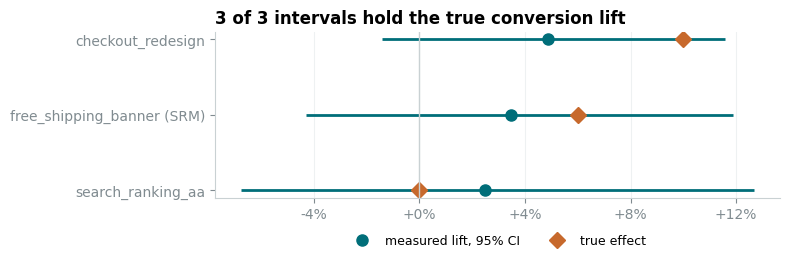

In [7]:
conversion = results[results["metric"] == "conversion_rate"].iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 2.8))
y = np.arange(len(conversion))
ax.hlines(y, conversion["ci_low"], conversion["ci_high"], color=theme.PRIMARY, linewidth=2)
ax.plot(conversion["measured"], y, "o", color=theme.PRIMARY, markersize=8, label="measured lift, 95% CI")
ax.plot(conversion["true_effect"], y, "D", color=theme.ACCENT, markersize=8, label="true effect")
ax.axvline(0, color="#c9d1d3", linewidth=1)
ax.set_yticks(y, [f"{name}{' (SRM)' if srm else ''}" for name, srm in conversion["srm_planted"].items()])
ax.xaxis.set_major_locator(MultipleLocator(0.04))
ax.xaxis.set_major_formatter(lambda value, _: f"{value:+.0%}")
held = conversion["truth_in_ci"].sum()
ax.set_title(f"{held} of {len(conversion)} intervals hold the true conversion lift")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False, fontsize=9)
ax.grid(axis="x", color="#eef1f2")
fig.tight_layout()

**Against the truth.** Every confidence interval contains `true_effect`. Two lessons sit in the table:

- `free_shipping_banner` fails the SRM check (B got about 46% of the sessions instead of 50%) and
  `has_sample_ratio_mismatch` confirms it was planted. Its lift must not be reported, however plausible it looks.
- `checkout_redesign` has a true lift of +10% and still misses significance on this seed. The test was sized for
  about 80% power, so roughly one seed in five ends like this. `search_ranking_aa` is an A/A test: no effect, and the
  interval sits around zero as it should.

## 2. Which customers come back?

A cohort is the month of a customer's first order. Retention in month *k* is the share of a cohort that orders again
*k* months later. One trap first: the shop is older than the data. `signup_date` in `customer_data` goes back to
2019, so for some customers the first order in the data is not their first order ever, and counting them would
inflate the early cohorts. The cohorts below keep only customers who signed up within the period.

In [8]:
orders = (data["sales_data"].groupby("order_id")
          .agg(customer_id=("customer_id", "first"), order_date=("order_date", "first"),
               value=("revenue_gross", "sum")))
month = orders["order_date"].dt.to_period("M")
first_month = month.groupby(orders["customer_id"]).transform("min")
orders["cohort"], orders["age_months"] = first_month, (month - first_month).apply(lambda offset: offset.n)
signup = data["customer_data"].set_index("customer_id")["signup_date"]
new_customers = orders["customer_id"].map(signup) >= orders["order_date"].min()
print(f"{new_customers.groupby(orders['customer_id']).first().mean():.0%} of the customers who ordered signed up "
      "within the period")

active = (orders[new_customers].groupby(["cohort", "age_months"])["customer_id"].nunique()
          .unstack(fill_value=0))
retention = active.div(active[0], axis=0).loc[:, 1:12]
retention = retention[retention.index <= retention.index.max() - 12]  # cohorts with 12 full months
retention.mean().rename("mean retention").to_frame().T.round(3)

86% of the customers who ordered signed up within the period


age_months,1,2,3,4,5,6,7,8,9,10,11,12
mean retention,0.114,0.108,0.096,0.091,0.082,0.079,0.073,0.064,0.062,0.062,0.056,0.056


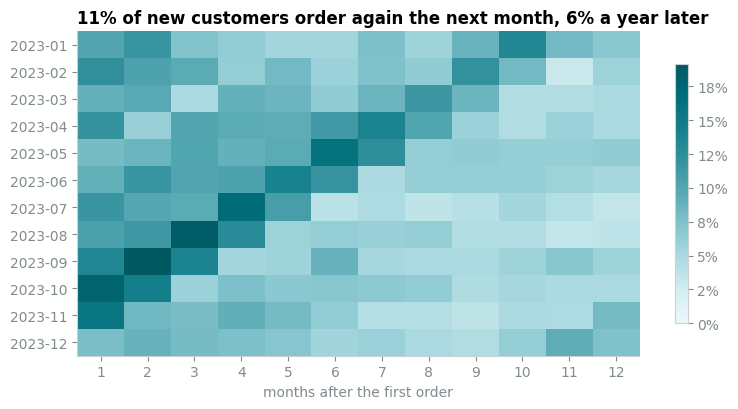

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.2))
teal = LinearSegmentedColormap.from_list("teal", theme.TEAL[:9])  # one hue, light to dark
image = ax.imshow(retention.to_numpy(), cmap=teal, vmin=0, aspect="auto")
ax.set_xticks(range(12), range(1, 13))
ax.set_yticks(range(len(retention)), [str(period) for period in retention.index])
ax.set_xlabel("months after the first order")
ax.set_title(f"{retention[1].mean():.0%} of new customers order again the next month, "
             f"{retention[12].mean():.0%} a year later")
fig.colorbar(image, ax=ax, format=lambda value, _: f"{value:.0%}", shrink=0.8)
fig.tight_layout()

Retention drops after the first month and then flattens. The dark diagonal is November 2023: every cohort
orders more in the Black Friday month, whatever its age, so seasonality shows up inside a cohort table too.
Retention flattens because a core of customers keeps buying while most never return. RFM puts a score on that:
recency (days since the last order), frequency (orders) and monetary value (revenue), each split into quintiles from
1 to 5 over the customers who ordered.

In [10]:
end = orders["order_date"].max()
rfm = orders.groupby("customer_id").agg(last_order=("order_date", "max"), frequency=("value", "size"),
                                        monetary=("value", "sum"))
rfm["recency_days"] = (end - rfm.pop("last_order")).dt.days
rfm["R"] = pd.qcut(rfm["recency_days"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm["frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["rfm_group"] = pd.cut(rfm[["R", "F", "M"]].sum(axis=1), [2, 6, 9, 12, 15],
                          labels=["at risk", "occasional", "steady", "best"])
rfm["rfm_group"].value_counts().sort_index()

rfm_group
at risk       5676
occasional    7981
steady        5621
best          3900
Name: count, dtype: int64

**Against the truth.** `customer_segment` in `customer_data` is the behaviour each customer was given
when the data was generated. How do the RFM groups line up with it?

In [11]:
segments = data["customer_data"].set_index("customer_id")["customer_segment"]
order = ["one_time", "occasional", "regular", "deal_hunter", "loyal"]
truth = pd.crosstab(rfm["rfm_group"], segments.reindex(rfm.index), normalize="index")[order]
truth.round(2)

customer_segment,one_time,occasional,regular,deal_hunter,loyal
rfm_group,,,,,
at risk,0.37,0.33,0.17,0.09,0.04
occasional,0.29,0.31,0.22,0.12,0.06
steady,0.10,0.25,0.31,0.19,0.15
best,0.00,0.09,0.27,0.28,0.36


In [12]:
revenue_by_segment = orders.groupby(orders["customer_id"].map(segments))["value"].sum()
revenue_share = revenue_by_segment / orders["value"].sum()
customers_share = segments.reindex(rfm.index).value_counts(normalize=True)
pd.DataFrame({"share_of_customers": customers_share, "share_of_revenue": revenue_share}).loc[order].round(3)

,share_of_customers,share_of_revenue
one_time,0.216,0.097
occasional,0.263,0.165
regular,0.237,0.224
deal_hunter,0.156,0.226
loyal,0.128,0.289


Three numbers per customer recover much of the hidden behaviour: the best RFM group is mostly loyal and
regular customers, and the at-risk group mostly one-time and occasional buyers. Deal hunters also land among the
best, because they buy often. RFM sees how much they buy, not that they wait for a discount; the share of discounted
lines per customer (`discount_rate` in `sales_data`) would set them apart. Loyal customers are a small part of the
base and bring an outsized share of revenue.

## 3. Which orders are fraud?

The shop wants a short list of orders to hold for review. Four red flags come from the order itself, without the
truth:

- shipped to a postal code other than the customer's own,
- paid by card,
- worth more than 95% of all orders,
- the customer placed two or more orders within three days.

In [13]:
sales = data["sales_data"]
order_view = (sales.groupby("order_id")
              .agg(customer_id=("customer_id", "first"), ordered_at=("order_datetime", "first"),
                   value=("revenue_gross", "sum"), payment=("payment_method", "first"),
                   ship_to=("shipping_postal_code", "first"), home=("postal_code", "first"))
              .sort_values("ordered_at"))
burst = (order_view.reset_index().set_index("ordered_at").groupby("customer_id")["order_id"]
         .rolling("3D").count().rename("orders_in_3_days").reset_index())
order_view = order_view.reset_index().merge(burst, on=["customer_id", "ordered_at"]) \
    .drop_duplicates("order_id").set_index("order_id")

flags = pd.DataFrame({
    "other_address": order_view["ship_to"] != order_view["home"],
    "card": order_view["payment"] == "Card",
    "high_value": order_view["value"] > order_view["value"].quantile(0.95),
    "burst": order_view["orders_in_3_days"] >= 2,
})
flags.mean().rename("share of orders").round(3)

other_address    0.065
card             0.226
high_value       0.050
burst            0.038
Name: share of orders, dtype: float64

Each flag alone catches far too many honest orders: people send gifts to other addresses and pay by card
every day. Together they narrow the list. **Against the truth**, `is_fraud` in `order_data` scores each rule:

In [14]:
is_fraud = data["order_data"].groupby("order_id")["is_fraud"].first().reindex(flags.index)
rules = {
    "other address": flags["other_address"],
    "other address + card": flags["other_address"] & flags["card"],
    "other address + card + high value": flags["other_address"] & flags["card"] & flags["high_value"],
    "all four flags": flags.all(axis=1),
    "at least three flags": flags.sum(axis=1) >= 3,
}
scores = pd.DataFrame({
    name: {"flagged": rule.sum(), "fraud caught": (rule & is_fraud).sum(),
           "precision": (rule & is_fraud).sum() / max(rule.sum(), 1),
           "recall": (rule & is_fraud).sum() / is_fraud.sum()}
    for name, rule in rules.items()}).T
scores.round(3)

,flagged,fraud caught,precision,recall
other address,3608.0,221.0,0.061,1.000
other address + card,1015.0,221.0,0.218,1.000
other address + card + high value,263.0,215.0,0.817,0.973
all four flags,178.0,177.0,0.994,0.801
at least three flags,322.0,220.0,0.683,0.995


Three flags give a review list of a few hundred orders that holds almost every fraud order. Adding the
burst flag makes the list nearly pure but misses the first order of each ring, which has no earlier order to form
a burst. `anomaly_data` lists every ring with its dates and the address it shipped to.

One caveat: in this data a fraud ring ships all its orders to one new postal code, and honest orders to another
address almost never repeat it, so "several orders to the same new address" separates fraud perfectly here. Real
data is noisier (offices, family, parcel lockers), so treat this question as the easy level of fraud detection.